# Security of Mobile Systems — Notebook 1
## Wireless Waves, Free-Space Path Loss and Received Power
**Student learning notebook | Lecture 1: AIR INTERFACE**

**No Sionna installation required.** Run the Python cells using NumPy and Matplotlib. The optional Sionna RT demonstration is performed by the instructor.

### Learning goals
- Explain frequency, wavelength.
- Explain the **axes** and physical meaning of each free-space path-loss graph.
- Investigate FSPL as a function of **distance** and **frequency**, changing only one variable at a time.
- Verify the **r to 2r** rule and distinguish **dB** (loss/difference) from **dBm** (absolute power).
- Discuss the limits of ideal free-space assumptions and possible security implications.

**Workflow:** Predict → Run → Observe → Explain → Experiment. Replace the prompts in the **Your answer** Markdown cells with your own answers. Run cells in order (Shift+Enter).

In [ ]:
import sys
import importlib.util
import subprocess

if importlib.util.find_spec("sionna") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "sionna-rt"
    ])
    print("Sionna RT installed.")
else:
    print("Sionna is already installed.")

Sionna RT installed.


In [ ]:
from sionna.rt import load_scene, Transmitter, Receiver, PathSolver

## Exercise 0 — Initial prediction (5 minutes)

A base station transmits at **3.5 GHz**. Receiver RX1 is approximately **50 m** away, and RX2 approximately **100 m** away.

**Before running any code:**
1. Which receiver do you expect to receive more power? Why?
2. If the frequency increases while distance stays fixed, what happens to wavelength?

### Your answer — Exercise 0
> Write your prediction here.

## Exercise 1 — Frequency and wavelength (10 minutes)

### Understanding wavelength and wave amplitude

The wavelength is calculated using:

$$
\lambda = \frac{c}{f}
$$

where:
- $\lambda$ is wavelength (m).
- $c$ is the speed of light (m/s).
- $f$ is frequency (Hz).

Since the frequency is given in GHz, we multiply by $10^9$:

$$
\lambda = \frac{c}{f_{\mathrm{GHz}}\times 10^9}
$$

To visualize a sinusoidal wave in space, we use:

$$
y(x) = \sin\left(\frac{2\pi x}{\lambda}\right)
$$

where:
- $x$ is position along the wave (m).
- $\lambda$ is wavelength (m).
- $y(x)$ is normalized amplitude, between -1 and +1.

One complete oscillation occupies one wavelength.



### Frequency and wavelength in mobile networks

Mobile networks use different frequency bands. The table below
shows representative examples from 2G to 5G.

| Generation | Technology | Example frequency | Wavelength |
|---|---|---:|---:|
| 2G | GSM | 900 MHz | 33.33 cm |
| 3G | UMTS | 2.1 GHz | 14.29 cm |
| 4G | LTE | 2.6 GHz | 11.54 cm |
| 5G | NR (mid-band) | 3.5 GHz | 8.57 cm |
| 5G | NR (mmWave) | 26 GHz | 1.15 cm |

**Note:** These are representative frequency bands. Each
mobile generation can operate at multiple frequencies.
Higher generations do not always use higher frequencies.


### Practical investigation: Two 5G frequency bands

We compare:

- **3.5 GHz:** A representative 5G mid-band frequency.
- **26 GHz:** A representative 5G millimeter-wave frequency.

Both waves are displayed over the same distance (10 cm).

**Before running the code, predict:**

1. How does carrier frequency affect the wavelength of a wireless signal?
2. Does a higher carrier frequency automatically mean a higher data rate?

**Task:** Run the Python cell, compare the graphs, and identify
the wavelength marked between two consecutive peaks.


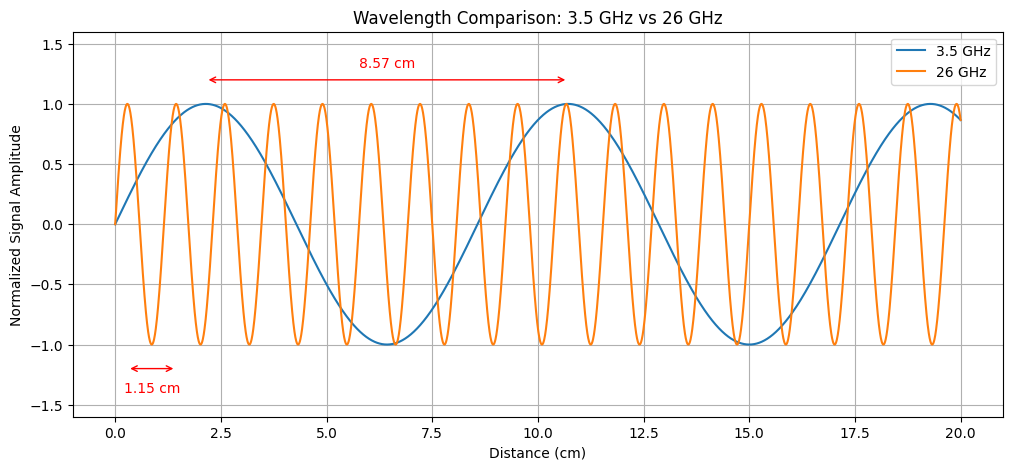

3.5 GHz wavelength = 8.57 cm
26 GHz wavelength = 1.15 cm


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Speed of light
c = 3e8

# Distance from 0 to 20 cm
x = np.linspace(0, 0.20, 3000)

# Frequencies
f1 = 3.5e9
f2 = 26e9

# Calculate wavelengths
w1 = c / f1
w2 = c / f2

# Generate waves
wave1 = np.sin(2 * np.pi * x / w1)
wave2 = np.sin(2 * np.pi * x / w2)

# Plot both waves
plt.figure(figsize=(12, 5))

plt.plot(x * 100, wave1, label="3.5 GHz")
plt.plot(x * 100, wave2, label="26 GHz")

# Wavelength of 3.5 GHz: peak to peak
start1 = w1 * 100 / 4
end1 = start1 + w1 * 100

plt.annotate("", xy=(end1, 1.2), xytext=(start1, 1.2),
             arrowprops=dict(arrowstyle="<->", color="red"))

plt.text((start1 + end1) / 2, 1.3,
         f"{w1*100:.2f} cm", color="red", ha="center")

# Wavelength of 26 GHz: peak to peak
start2 = w2 * 100 / 4
end2 = start2 + w2 * 100

plt.annotate("", xy=(end2, -1.2), xytext=(start2, -1.2),
             arrowprops=dict(arrowstyle="<->", color="red"))

plt.text((start2 + end2) / 2, -1.4,
         f"{w2*100:.2f} cm", color="red", ha="center")

# Display graph
plt.xlabel("Distance (cm)")
plt.ylabel("Normalized Signal Amplitude")
plt.title("Wavelength Comparison: 3.5 GHz vs 26 GHz")
plt.ylim(-1.6, 1.6)
plt.legend()
plt.grid()
plt.show()

# Print wavelengths
print(f"3.5 GHz wavelength = {w1*100:.2f} cm")
print(f"26 GHz wavelength = {w2*100:.2f} cm")


### Your answer — Exercise 1
1. What do the horizontal and vertical axes represent?
2. Which curve has more oscillations over 0.40 m?
3. Which wavelength is shorter, and how does the formula $\lambda=c/f$ explain this?

> Write your answers here.

## Exercise 1B — From Carrier Frequency to Data Rate (10 minutes)

### Learning objective

Understand the difference between carrier frequency, bandwidth,
and data rate.

 **1. Does having more oscillations mean that we automatically transmit more bits?**


 **2. What is the relationship between frequency and data rate?**


**At lower frequencies, much of the spectrum is already allocated to television, mobile networks, aviation, and other services. Finding a large, continuous block of unused spectrum can be difficult.**

At higher frequencies, regulators can sometimes make much wider contiguous blocks available.

**Bandwidth** describes the width of the frequency range
available for transmitting information.

**Data rate** is the number of information bits transmitted
per second.

### 2. Example: Two 5G systems

| Parameter | System A | System B |
|---|---|---|
| Carrier frequency | 3.5 GHz | 26 GHz |
| Channel bandwidth | 100 MHz | 100 MHz |
| Assumed spectral efficiency | 4 bit/s/Hz | 4 bit/s/Hz |
| Idealized data rate | 400 Mbps | 400 Mbps |

| Parameter | System A | System B |
|---|---|---|
| Carrier frequency | 3.5 GHz | 26 GHz |
| Channel bandwidth | 100 MHz | 400 MHz |
| Assumed spectral efficiency | 4 bit/s/Hz | 4 bit/s/Hz |
| Idealized data rate | 400 Mbps | 1600 Mbps |



These are illustrative configurations, not guaranteed
real-world 5G throughput values.

### 3. Simplified data-rate model

$$
R = B \times \eta
$$

where:

- $R$: data rate in bits per second (bit/s)
- $B$: bandwidth in hertz (Hz)
- $\eta$: spectral efficiency in bit/s/Hz

This simplified model assumes the same spectral efficiency
for both systems and ignores protocol overhead.
$$
\eta = 4 \text{ bit/s/Hz}
$$

This means every hertz of bandwidth supports an average of 4 information bits per second in our idealized model.

### Before running the code

1. If bandwidth doubles, what happens to data rate when
   spectral efficiency stays constant?
2. If carrier frequency increases but bandwidth stays
   unchanged, does data rate necessarily increase?
3. Why might a 26 GHz system support higher data rates
   than a 3.5 GHz system?


Carrier: 3.5 GHz | Bandwidth: 100 MHz | Data rate: 400 Mbps
Carrier: 26 GHz | Bandwidth: 400 MHz | Data rate: 1600 Mbps


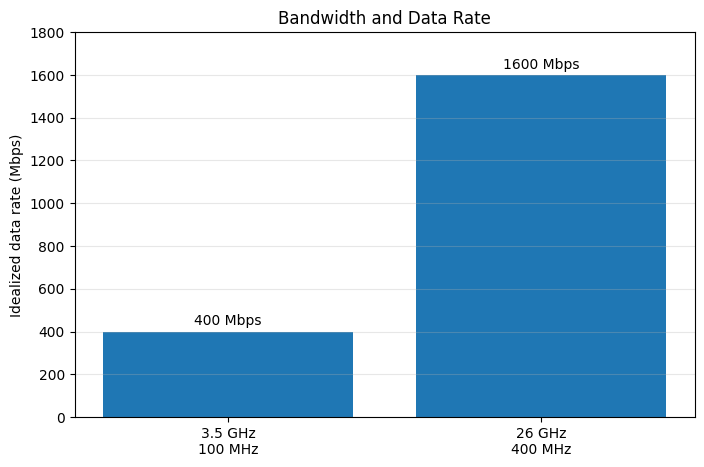

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Define the two example systems
# --------------------------------------------------

# Carrier frequencies in GHz
carrier_ghz = [3.5, 26]

# Available bandwidth in MHz
bandwidth_mhz = [100, 400]

# Assume both systems have the same spectral efficiency.
# This means 4 information bits per second per Hz.
spectral_efficiency = 4  # bit/s/Hz

# --------------------------------------------------
# 2. Calculate idealized data rates
# --------------------------------------------------

# Convert bandwidth from MHz to Hz.
bandwidth_hz = np.array(bandwidth_mhz) * 1e6

# R = B × spectral efficiency
data_rate_bps = bandwidth_hz * spectral_efficiency

# Convert bit/s to Mbps.
data_rate_mbps = data_rate_bps / 1e6

# Display the results.
for f, b, rate in zip(
    carrier_ghz, bandwidth_mhz, data_rate_mbps
):
    print(
        f"Carrier: {f} GHz | "
        f"Bandwidth: {b} MHz | "
        f"Data rate: {rate:.0f} Mbps"
    )


# 3. Plot the comparison


labels = ["3.5 GHz\n100 MHz", "26 GHz\n400 MHz"]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, data_rate_mbps)

plt.ylabel("Idealized data rate (Mbps)")
plt.title("Bandwidth and Data Rate")
plt.ylim(0, 1800)
plt.grid(axis="y", alpha=0.3)

# Show the data rate above each bar.
for bar, rate in zip(bars, data_rate_mbps):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f"{rate:.0f} Mbps",
        ha="center"
    )

plt.show()


# 4. What if both systems have the SAME bandwidth?

same_bandwidth_mhz = 100

same_data_rate_mbps = (
    same_bandwidth_mhz * spectral_efficiency
)




1. If bandwidth doubles, what happens to data rate when
   spectral efficiency stays constant?
2. If carrier frequency increases but bandwidth stays
   unchanged, does data rate necessarily increase?
3. Why might a 26 GHz system support higher data rates
   than a 3.5 GHz system?
   ## Exercise 2B — From Carrier Frequency to Data Rate (10 minutes)
   
**If two systems operate at carrier frequencies of 3.5 GHz and 26 GHz, but both have the same bandwidth of 100 MHz and a spectral efficiency of 4 bit/s/Hz, will their data rates be different?**

> Write your answers here.

$$
R = B \times \eta
$$

For both systems:

$$
R = 100 \times 10^6 \times 4 = 400 \text{ Mbps}
$$



Carrier: 3.5 GHz | Bandwidth: 100 MHz | Data rate: 400 Mbps
Carrier: 26 GHz | Bandwidth: 100 MHz | Data rate: 400 Mbps


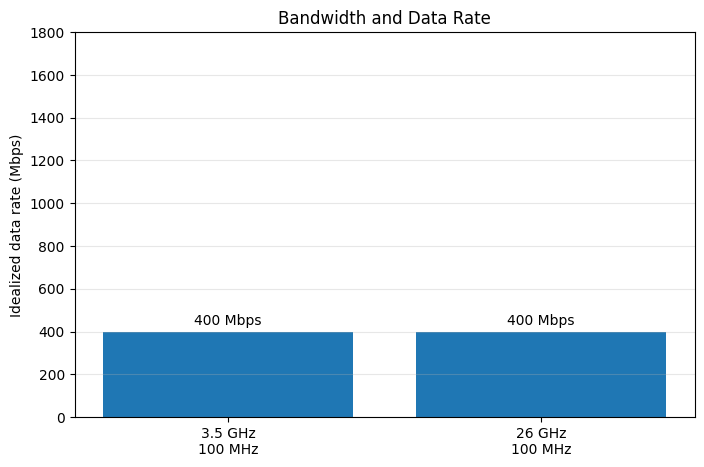

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Define the two example systems
# --------------------------------------------------

# Carrier frequencies in GHz
carrier_ghz = [3.5, 26]

# Available bandwidth in MHz
bandwidth_mhz = [100, 100]

# Assume both systems have the same spectral efficiency.
# This means 4 information bits per second per Hz.
spectral_efficiency = 4  # bit/s/Hz

# --------------------------------------------------
# 2. Calculate idealized data rates
# --------------------------------------------------

# Convert bandwidth from MHz to Hz.
bandwidth_hz = np.array(bandwidth_mhz) * 1e6

# R = B × spectral efficiency
data_rate_bps = bandwidth_hz * spectral_efficiency

# Convert bit/s to Mbps.
data_rate_mbps = data_rate_bps / 1e6

# Display the results.
for f, b, rate in zip(
    carrier_ghz, bandwidth_mhz, data_rate_mbps
):
    print(
        f"Carrier: {f} GHz | "
        f"Bandwidth: {b} MHz | "
        f"Data rate: {rate:.0f} Mbps"
    )

# --------------------------------------------------
# 3. Plot the comparison
# --------------------------------------------------

labels = ["3.5 GHz\n100 MHz", "26 GHz\n100 MHz"]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, data_rate_mbps)

plt.ylabel("Idealized data rate (Mbps)")
plt.title("Bandwidth and Data Rate")
plt.ylim(0, 1800)
plt.grid(axis="y", alpha=0.3)

# Show the data rate above each bar.
for bar, rate in zip(bars, data_rate_mbps):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30,
        f"{rate:.0f} Mbps",
        ha="center"
    )

plt.show()



## Exercise 3 — Free-space path loss (20 minutes)

### Background: what is path loss?
When radio waves spread through free space, received power becomes smaller as the separation between isotropic antennas increases. **Free-space path loss (FSPL)** expresses the reduction between transmitted and received power as a ratio in **decibels (dB)**.

$$FSPL(d,f)=20\log_{10}\left(\frac{4\pi d}{\lambda}\right)
=20\log_{10}\left(\frac{4\pi df}{c}\right)$$

where $d$ is separation (m), $f$ is frequency (Hz), $\lambda=c/f$ is wavelength (m), and $c$ is the speed of light (m/s).



**Important:** This ideal model assumes free-space propagation and isotropic antennas. In this exercise we vary **one parameter at a time**.



### Exercise 3A — Path loss vs. frequency

Now keep the **distance fixed at 100 m**, and vary the frequency from 1 to 10 GHz.

**Trade-off:**
Lower-frequency bands are often attractive for coverage, while higher-frequency bands can be attractive for providing very wide channels and high capacity in suitable environments.But higher frequencies can also introduce propagation and coverage challenges.


  
- Why db?

Because the free-space propagation model predicts the ratio between transmitted and received power using distance and frequency.
dB expresses the ratio between two power levels on a logarithmic scale.

**Predict:** Which has higher FSPL at 100 m: 3.5 GHz or 6 GHz? Why?


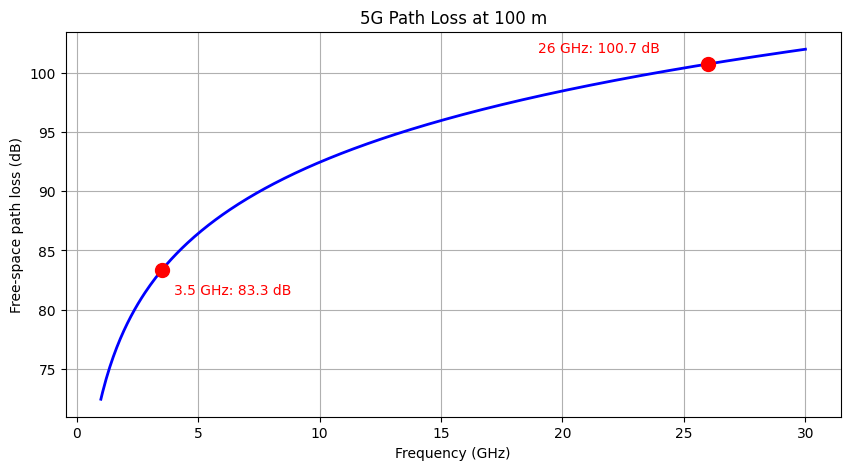

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Speed of light (m/s)
c = 3e8

# Fixed distance: 100 meters
distance = 100

# Frequency range: 1 to 30 GHz
f = np.linspace(1, 30, 400)

# Free-space path loss (d in meters, f in GHz)
def fspl(d, f):
    frequency_hz = f * 1e9  # Convert GHz to Hz

    return 20 * np.log10(4 * np.pi * d * frequency_hz / c)

# Calculate path loss
loss = fspl(distance, f)

# Two 5G frequencies
loss1 = fspl(distance, 3.5)
loss2 = fspl(distance, 26)

# Draw the blue curve
plt.figure(figsize=(10, 5))
plt.plot(f, loss, color="blue", linewidth=2)

# Two red points
plt.scatter(3.5, loss1, color="red", s=100, zorder=5)
plt.scatter(26, loss2, color="red", s=100, zorder=5)

# Labels beside the red points
plt.text(4, loss1 - 2, f"3.5 GHz: {loss1:.1f} dB", color="red")
plt.text(19, loss2 + 1, f"26 GHz: {loss2:.1f} dB", color="red")

plt.xlabel("Frequency (GHz)")
plt.ylabel("Free-space path loss (dB)")
plt.title("5G Path Loss at 100 m")
plt.grid()
plt.show()

### Exercise 3B — Path loss vs. distance

- **Frequency stays fixed:** 3.5 GHz.


**Predict:** What happens to FSPL as distance increases? What happens from 50 m to 100 m?

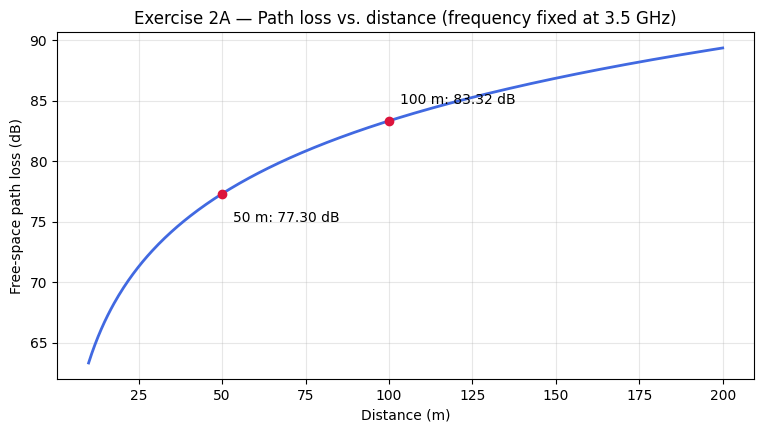

In [ ]:
# Shared free-space model — run this cell before later exercises
#creates a Python function called fspl_db

def fspl_db(distance_m, frequency_ghz):

    #np.asarray() converts the input into a NumPy array
    #dtype=float ensures the values are floating-point numbers.
    distance_m = np.asarray(distance_m, dtype=float)

    #converts the frequency from GHz to Hz.
    frequency_hz = np.asarray(frequency_ghz, dtype=float)*1e9

    #implements the free-space path-loss equation
    return 20*np.log10(4*np.pi*distance_m*frequency_hz/c)

#Fix the frequency
fixed_frequency_ghz = 3.5

#creates 400 evenly spaced distances between 10 and 200 meters
distances_m = np.linspace(10, 200, 400)

#Calculate FSPL for every distance
#This calculates 400 path-loss values.
loss_by_distance = fspl_db(distances_m, fixed_frequency_ghz)

#Draw the curve
fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(distances_m, loss_by_distance, lw=2, color='royalblue')

#marks two points in red
for d in [50,100]:
    loss = fspl_db(d,fixed_frequency_ghz)
    ax.scatter([d],[loss],color='crimson',zorder=4)
    ax.annotate(f'{d} m: {loss:.2f} dB',(d,loss),xytext=(8,-20 if d==50 else 12),
                textcoords='offset points')

ax.set(xlabel='Distance (m)',ylabel='Free-space path loss (dB)',
       title='Exercise 2A — Path loss vs. distance (frequency fixed at 3.5 GHz)')
ax.grid(alpha=.3)
plt.show()

### Your answer — Exercise 3A
1. What does the **x-axis** show? What does the **y-axis** show?
2. At a fixed frequency, does loss increase or decrease with distance?
3. Compare the loss at 50 m and 100 m. What is the difference in dB?

> Write your answers here.

-  **dB measures a ratio or difference between two power levels**.
  
-  **dBm measures an absolute power level relative to 1 milliwatt**.


### Why is path loss expressed in decibels (dB)?
- FSPL measures a ratio or difference between two power levels, Transmitted power and recieved power; expressed in db.

In free-space propagation, we compare two powers:

- **\(P_t\):** Transmitted power
- **\(P_r\):** Received power

The path-loss formula is:

$$
\boxed{L_{\mathrm{dB}}=10\log_{10}\left(\frac{P_t}{P_r}\right)}
$$

### Example: Path loss of 77.30 dB

A free-space path loss of 78 dB means the received power is 78 decibels lower than the transmitted power.

$$
\frac{P_t}{P_r}
$$
**Transmitted power:** 100 W

**Received power:** Approximately 1.862 µW

$$
L_{\mathrm{dB}}=10\log_{10}\left(\frac{100}{0.000001862}\right)
$$

$$
\boxed{L_{\mathrm{dB}}\approx 77.30\text{ dB}}
$$

**Why use dB?**

Because received power can be millions of times smaller than transmitted power. The logarithmic decibel scale makes these large power ratios easier to express, compare, and calculate.



### Your answer — Exercise 2B
1. Which variable changes in this graph, and which stays fixed?
2. How does FSPL change when frequency increases?
3. Explain the result using $FSPL(d,f)=20\log_{10}(4\pi df/c)$.

> Write your answers here.

## Exercise 4 — The $r$ and $2r$ experiment (15 minutes)

### What do $r$ and $2r$ mean?
- $r$ is a reference **transmitter–receiver separation**.
- $2r$ means **twice that separation**.
- In this exercise, choose $r=50$ m and $2r=100$ m. Keep frequency fixed at 3.5 GHz.

**Mathematical prediction:**

$$\begin{aligned}
FSPL(2r)-FSPL(r)
&=20\log_{10}\left(\frac{4\pi(2r)}{\lambda}\right)
-20\log_{10}\left(\frac{4\pi r}{\lambda}\right)\\
&=20\log_{10}(2)\approx 6.02\;\mathrm{dB}.
\end{aligned}$$

Therefore **doubling distance adds about 6 dB of free-space path loss** at a fixed frequency.


r = 50 m: FSPL = 77.30 dB
2r = 100 m: FSPL = 83.32 dB
Increase in loss = 6.02 dB


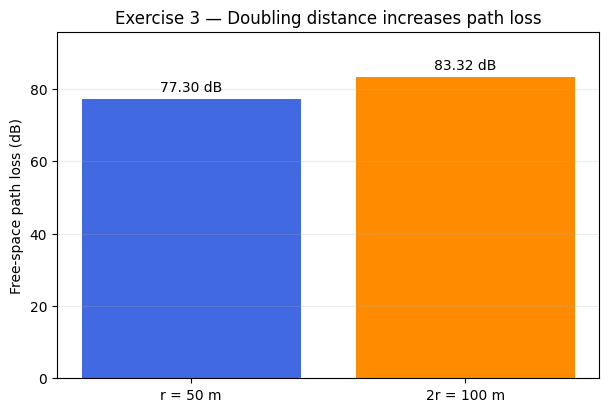

In [ ]:
# Exercise 3: What happens to path loss when distance doubles?

# Step 1: Define the initial distance and frequency
r_m = 50.0          # Initial distance: 50 meters
frequency_ghz = 3.5 # Frequency: 3.5 GHz (fixed)

# Step 2: Calculate path loss at the initial distance (r)
loss_r = fspl_db(r_m, frequency_ghz)

# Step 3: Calculate path loss at twice the distance (2r)
loss_2r = fspl_db(2*r_m, frequency_ghz)

# Step 4: Calculate the difference
difference_db = loss_2r-loss_r

# Step 5: Print the results
print(f'r = {r_m:.0f} m: FSPL = {loss_r:.2f} dB')
print(f'2r = {2*r_m:.0f} m: FSPL = {loss_2r:.2f} dB')
print(f'Increase in loss = {difference_db:.2f} dB')

# Step 6: Create a figure and axes
fig,ax=plt.subplots(figsize=(7,4.5))

# Step 7: Draw two bars to compare the path losses
bars=ax.bar(['r = 50 m','2r = 100 m'],[loss_r,loss_2r],color=['royalblue','darkorange'])

# Step 8: Display the path-loss value above each bar
ax.bar_label(bars,fmt='%.2f dB',padding=3)

# Step 9: Add the y-axis label and chart title
ax.set(ylabel='Free-space path loss (dB)',title='Exercise 3 — Doubling distance increases path loss')

# Step 10: Set the vertical axis range
ax.set_ylim(0,max(loss_r,loss_2r)*1.15)

# Step 11: Add horizontal grid lines
ax.grid(axis='y',alpha=.25)

# Step 12: Display the chart
plt.show()


### Exercise 4A — Why does 6 dB mean one-quarter of the power?
inverse-square law

In free-space propagation, received power decreases with the square of distance:

$$
P_r \propto \frac{1}{d^2}
$$

Therefore, if we double the distance:

$$
\frac{P_r(2d)}{P_r(d)}
= \left(\frac{d}{2d}\right)^2
= \frac{1}{4}
= 0.25
$$

This means the receiver at twice the distance gets **25% of the original received power**.

#### Expressing the change in decibels

The change in received power is:

$$
\Delta P_{\mathrm{dB}}
= 10\log_{10}\left(\frac{P_2}{P_1}\right)
$$

Substituting the power ratio:

$$
\Delta P_{\mathrm{dB}}
= 10\log_{10}(0.25)
\approx -6.02\ \mathrm{dB}
$$

**Important distinction:**

- Free-space path loss **increases by +6.02 dB**.
- Received power **decreases by -6.02 dB**.
- The second receiver gets **one-quarter of the first receiver's power**.

This assumes ideal free-space propagation, with unchanged transmit power and antenna gains.


### Your answer — Exercise 3
1. By how many dB does FSPL change from $r$ to $2r$?
2. Does the **6 dB rule** depend on whether $r$ is 50 m or 100 m, under the ideal free-space model?
3. If the received power is 4 times smaller, how many dB is the change?

> Write your answers here.

**Try it:** Change `r_m` to 25 or 100, rerun the cell, and check whether the difference changes.

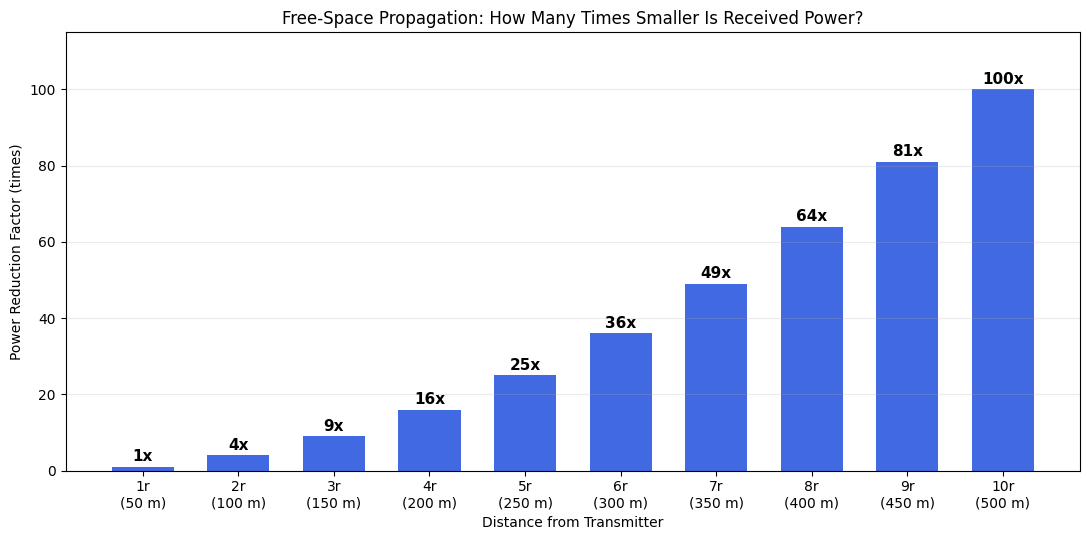

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters
frequency_ghz = 3.5
d1 = 50
max_multiplier = 10

# Distance multipliers
multipliers = np.arange(1, max_multiplier + 1)
distances = d1 * multipliers

# Calculate FSPL
loss1 = fspl_db(d1, frequency_ghz)
losses = np.array([
    fspl_db(d, frequency_ghz) for d in distances
])

additional_loss = losses - loss1

# Calculate how many times smaller the power becomes
power_ratio = 10 ** (-additional_loss / 10)
reduction_factor = 1 / power_ratio

# Visualization
fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.bar(
    multipliers,
    reduction_factor,
    color="royalblue",
    width=0.65
)

for bar, factor in zip(bars, reduction_factor):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{factor:.0f}x",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(multipliers)
ax.set_xticklabels([
    f"{n}r\n({d} m)"
    for n, d in zip(multipliers, distances)
])

ax.set_xlabel("Distance from Transmitter")
ax.set_ylabel("Power Reduction Factor (times)")
ax.set_title(
    "Free-Space Propagation: How Many Times Smaller Is Received Power?"
)

ax.set_ylim(0, max(reduction_factor) * 1.15)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## Exercise 4B — From path loss to received power (10 minutes)

Path loss is a **ratio** measured in dB. Received power is an **absolute power level** measured in dBm.

dbm expresses an absolute power level using 1 milliwatt as the reference

For ideal isotropic antennas (0 dBi gains), without additional system losses:

$$P_r(\mathrm{dBm})=P_t(\mathrm{dBm})-FSPL(\mathrm{dB})$$

Choose $P_t=30$ dBm (1 W). Compare received power at $r$ and $2r$.

**Predict:** If FSPL increases by 6.02 dB, how does received power change?


### Understanding Power Levels: dB, dBm, and mW

In wireless communication, we distinguish between:

- **dB (decibel):** A logarithmic ratio between two power levels.
- **dBm:** An absolute power level referenced to 1 milliwatt.
- **mW:** A unit of physical power.
- Every decrease of 10 dBm means the power becomes 10 times smaller.
- dBm = a power level.
- dB = a ratio or change in power.



We convert power from milliwatts to dBm using:

$$
P_{\mathrm{dBm}} = 10\log_{10}\left(\frac{P_{\mathrm{mW}}}{1\ \mathrm{mW}}\right)
$$

Some useful reference values:

| Power (mW) | Power (dBm) |
|---|---|
| 1000 | +30 |
| 100 | +20 |
| 10 | +10 |
| 1 | 0 |
| 0.1 | -10 |
| 0.01 | -20 |
| 0.001 | -30 |

A negative dBm value does not mean negative physical power. It means the power is below 1 mW.

For ideal isotropic antennas with no additional losses:

$$
P_r(\mathrm{dBm}) = P_t(\mathrm{dBm}) - \mathrm{FSPL(dB)}
$$

We use a transmitted power of 30 dBm (1 W) and compare the received power at 50 m and 100 m.


Power conversion: mW to dBm
--------------------------------
1000 mW = +30 dBm
100 mW = +20 dBm
10 mW = +10 dBm
1 mW = +0 dBm
0.1 mW = -10 dBm
0.01 mW = -20 dBm
0.001 mW = -30 dBm


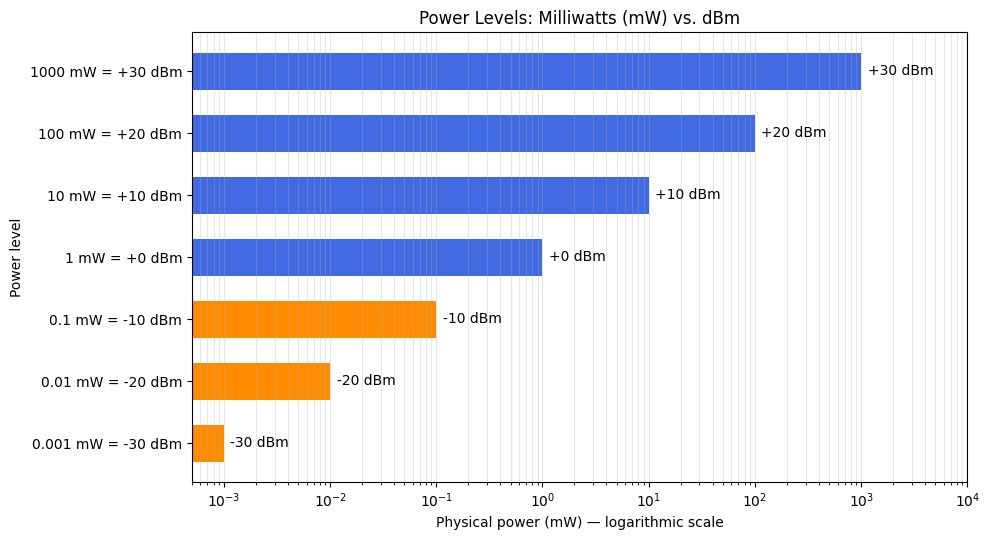

In [ ]:


import numpy as np
import matplotlib.pyplot as plt

# Example power levels in milliwatts
power_mw = np.array([1000, 100, 10, 1, 0.1, 0.01, 0.001])

# Convert mW to dBm
power_dbm = 10 * np.log10(power_mw)

# Print the conversions
print("Power conversion: mW to dBm")
print("-" * 32)

for mw, dbm in zip(power_mw, power_dbm):
    print(f"{mw:g} mW = {dbm:+.0f} dBm")

# Create the diagram
fig, ax = plt.subplots(figsize=(10, 5.5))

# Horizontal bars
y = np.arange(len(power_mw))
colors = [
    "royalblue" if dbm >= 0 else "darkorange"
    for dbm in power_dbm
]

bars = ax.barh(
    y,
    power_mw,
    color=colors,
    height=0.6
)

# Use logarithmic scale because power varies greatly
ax.set_xscale("log")

# Show the power levels on the vertical axis
ax.set_yticks(y)
ax.set_yticklabels([
    f"{mw:g} mW = {dbm:+.0f} dBm"
    for mw, dbm in zip(power_mw, power_dbm)
])

# Put highest power at the top
ax.invert_yaxis()

# Add labels to the end of each bar
for bar, dbm in zip(bars, power_dbm):
    ax.text(
        bar.get_width() * 1.15,
        bar.get_y() + bar.get_height() / 2,
        f"{dbm:+.0f} dBm",
        va="center",
        fontsize=10
    )

ax.set_xlim(0.0005, 10000)
ax.set_xlabel("Physical power (mW) — logarithmic scale")
ax.set_ylabel("Power level")
ax.set_title("Power Levels: Milliwatts (mW) vs. dBm")
ax.grid(axis="x", alpha=0.3, which="both")

plt.tight_layout()
plt.show()



### Your answer — Exercise 4
1. Why is the received power at $2r$ **more negative** in dBm?
2. What is the difference between **dB** and **dBm**?
3. Does a 6.02 dB drop mean half the received power or about one-quarter?

> Write your answers here.

## Exercise 5 — detection and privacy (10 minutes)
### Security Connection — Can an Unintended Receiver Detect the Signal?

In the previous exercise, we observed that doubling the distance from 50 m to 100 m reduces received power to **25%** of its previous value.

Now consider a wireless security scenario:

- **TX:** A transmitter sends a wireless signal.
- **RX1:** An authorized receiver is located 50 m from TX.
- **Observer:** An unintended receiver is located 100 m from TX.

Under ideal free-space conditions, with the same antenna gains:

$$
\frac{P_{\text{observer}}}{P_{\text{RX1}}}
=
\left(\frac{50}{100}\right)^2
=
0.25
$$

The observer receives only **25% of the power** received by RX1.

However, a weaker signal does not necessarily mean that the observer cannot detect the transmission.

An unintended observer may detect when a device is transmitting, even without being able to decode or understand its messages.

**Important:** FSPL describes how received power changes with distance. It does not determine whether a transmission can be detected or decoded.

### Security and Privacy: Traffic Analysis

**Detecting a transmission does not mean decoding or decrypting its content.**

Even when messages are encrypted, an observer may detect communication activity and identify patterns.

**Example: Military Communications**

During a war, a sudden increase in radio transmissions at night might suggest unusual military activity or preparations for an operation.

An observer cannot read the encrypted messages but may infer information from the transmission patterns.

**Key Takeaways:**

1. **Detection:** Identifying that a transmission is occurring.

2. **Decoding:** Recovering the transmitted data.

3. **Decryption:** Recovering the original message from encrypted data using the appropriate key.

4. **Traffic analysis:** Inferring information from communication patterns without reading message content.

**Conclusion:** Encryption protects message content but does not necessarily hide communication activity or patterns.


#### Question

**Does doubling the distance guarantee that an attacker cannot detect a wireless transmission?**

**Expected Answer:** No. The received signal becomes weaker, but detection also depends on receiver sensitivity, noise, and interference.

**Key Takeaway:** Wireless transmissions may be observable by unintended receivers, even when their received signal power is much lower.



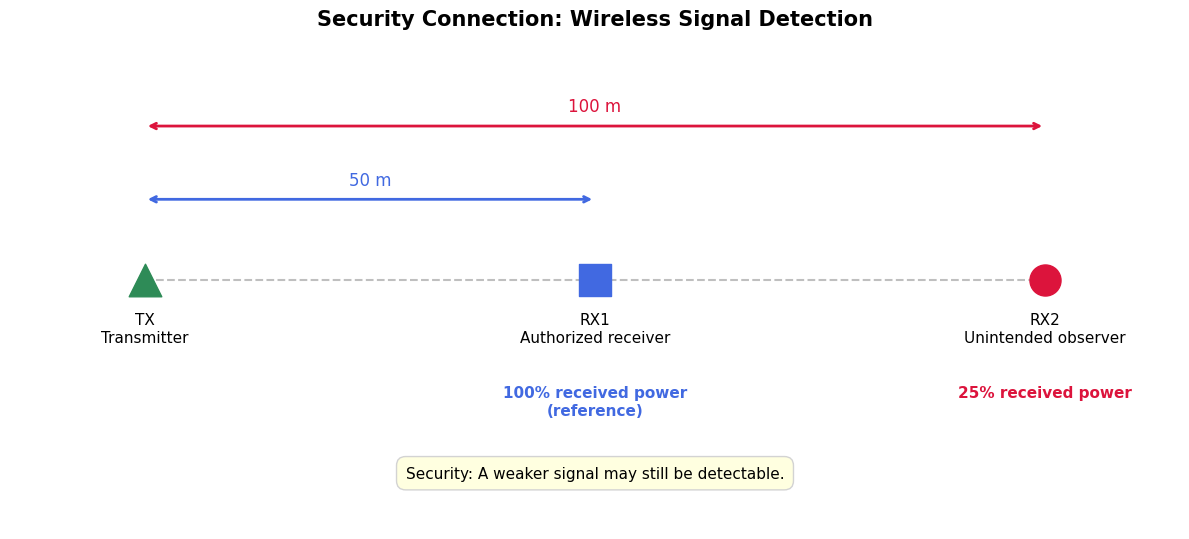

In [ ]:


import matplotlib.pyplot as plt

# Positions of the transmitter and receivers
tx_x = 0
rx_x = 50
observer_x = 100

# Relative received power
power_rx1 = 100
power_observer = (rx_x / observer_x) ** 2 * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 5.5))

# --------------------------------------------------
# 1. Draw the wireless communication path
# --------------------------------------------------
ax.plot(
    [tx_x, observer_x], [0, 0],
    linestyle="--", color="gray",
    linewidth=1.5, alpha=0.5, zorder=1
)

# --------------------------------------------------
# 2. Draw transmitter and receivers
# --------------------------------------------------
ax.scatter(tx_x, 0, s=550, color="seagreen",
           marker="^", zorder=5)

ax.scatter(rx_x, 0, s=500, color="royalblue",
           marker="s", zorder=5)

ax.scatter(observer_x, 0, s=500, color="crimson",
           marker="o", zorder=5)

# Device labels BELOW the symbols
ax.text(tx_x, -0.22, "TX\nTransmitter",
        ha="center", va="top", fontsize=11)

ax.text(rx_x, -0.22, "RX1\nAuthorized receiver",
        ha="center", va="top", fontsize=11)

ax.text(observer_x, -0.22, "RX2\nUnintended observer",
        ha="center", va="top", fontsize=11)

# --------------------------------------------------
# 3. Draw distance arrows ABOVE the devices
# --------------------------------------------------
ax.annotate(
    "", xy=(rx_x, 0.55), xytext=(tx_x, 0.55),
    arrowprops=dict(arrowstyle="<->",
                    color="royalblue", lw=2)
)

ax.text(25, 0.65, "50 m",
        ha="center", color="royalblue", fontsize=12)

ax.annotate(
    "", xy=(observer_x, 1.05), xytext=(tx_x, 1.05),
    arrowprops=dict(arrowstyle="<->",
                    color="crimson", lw=2)
)

ax.text(50, 1.15, "100 m",
        ha="center", color="crimson", fontsize=12)

# --------------------------------------------------
# 4. Display received power BELOW device labels
# --------------------------------------------------
ax.text(rx_x, -0.72, "100% received power\n(reference)",
        ha="center", va="top",
        color="royalblue", fontsize=11,
        fontweight="bold")

ax.text(observer_x, -0.72, f"{power_observer:.0f}% received power",
        ha="center", va="top",
        color="crimson", fontsize=11,
        fontweight="bold")

# --------------------------------------------------
# 5. Security message at the bottom
# --------------------------------------------------
ax.text(
    50, -1.35,
    "Security: A weaker signal may still be detectable.",
    ha="center", fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="lightyellow",
        edgecolor="lightgray"
    )
)

# --------------------------------------------------
# 6. Figure formatting
# --------------------------------------------------
ax.set_xlim(-15, 115)
ax.set_ylim(-1.7, 1.55)

ax.set_title(
    "Security Connection: Wireless Signal Detection",
    fontsize=15, fontweight="bold", pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()


## Exit ticket (5 minutes)

1. What is wavelength, and how does it change when frequency increases?
2. Which graph has **distance** on the x-axis? Which has **frequency**?
3. What happens to free-space path loss from $r$ to $2r$?
4. What happens to received power from $r$ to $2r$?
5. Why is free-space path loss not the same as a full Sionna RT propagation simulation?

### Your exit ticket
> Write your answers here.
